In [1]:
import osmnx as ox
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt

print("OSMnx version:", ox.__version__)

OSMnx version: 2.1.1


Counties loaded: 9
Coordinate system: EPSG:26910


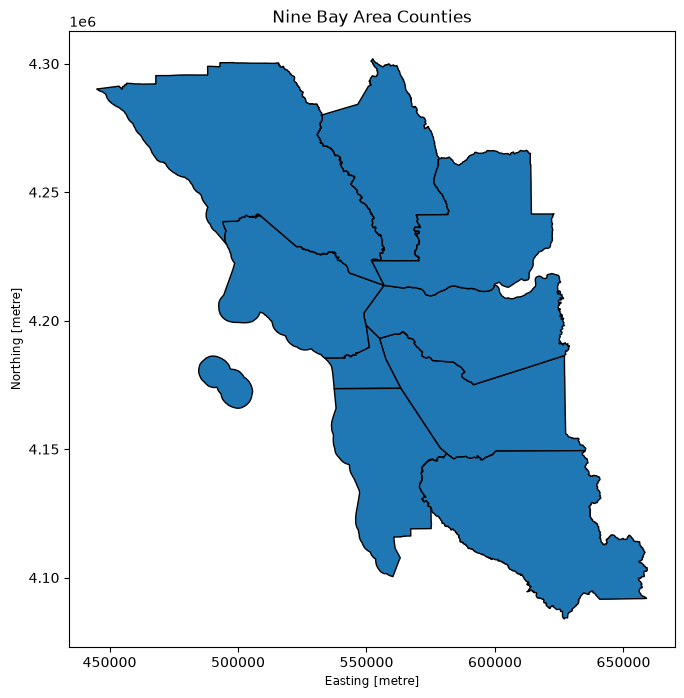

In [2]:
# Load the nine Bay Area county boundaries
counties = gpd.read_file(
    "data/processed/bay_area_counties.gpkg"
)

print("Counties loaded:", len(counties))
print("Coordinate system:", counties.crs)

# Plot county boundaries
counties.plot(
    figsize=(8, 8),
    edgecolor="black"
)

plt.title("Nine Bay Area Counties")
plt.show()

## Road Network Data Processing

**Source:** Geofabrik Northern California OpenStreetMap extract, October 27, 2026.

**Method:**
1. Collected boundaries for the nine Bay Area counties using OSMnx.
2. Combined the county geometries and exported a GeoJSON boundary.
3. Used `osmium extract` to clip the Northern California OSM data to the nine-county region.
4. Used `osmium tags-filter` to retain selected road categories and relevant referenced objects.
5. Converted the filtered PBF to OSM XML using `osmium cat`.
6. Built a directed road graph using `ox.graph_from_xml()` and saved it as GraphML.
7. Exported nodes and edges as GeoPackages in EPSG:26910.

**Primary output:** `data/processed/bay_area_drive.graphml`

The raw OSM input and intermediate XML files are not committed to GitHub. This notebook loads the processed network instead of repeating the expensive preprocessing steps.

In [3]:
# Load the already-processed road network
G_bay = ox.io.load_graphml(
    "data/processed/bay_area_drive.graphml"
)

print("Nodes:", len(G_bay.nodes))
print("Edges:", len(G_bay.edges))

Nodes: 729478
Edges: 1749823


In [4]:
# Find connected components in the road network
components = list(
    nx.weakly_connected_components(G_bay)
)

# Identify the largest connected component
largest_component = max(components, key=len)

print("Number of components:", len(components))
print("Largest component size:", len(largest_component))

# Create the main road network for routing
G_main = G_bay.subgraph(largest_component)

Number of components: 715
Largest component size: 726851


In [5]:
# Starting point: Downtown San Francisco
start_lat, start_lon = 37.7749, -122.4194

# Destination: SFO reference coordinate
end_lat, end_lon = 37.6213, -122.3790

# Snap both points to the main connected network
start = ox.distance.nearest_nodes(
    G_main, start_lon, start_lat
)

end, snap_distance = ox.distance.nearest_nodes(
    G_main,
    end_lon,
    end_lat,
    return_dist=True
)

# Calculate shortest driving route by distance
route = ox.routing.shortest_path(
    G_main,
    start,
    end,
    weight="length"
)

print("Route found:", route is not None)
print("Endpoint snap distance:",
      round(snap_distance, 2), "meters")

if route is not None:
    print("Number of route nodes:", len(route))

Route found: True
Endpoint snap distance: 332.39 meters
Number of route nodes: 143


Route distance: 20.9 km


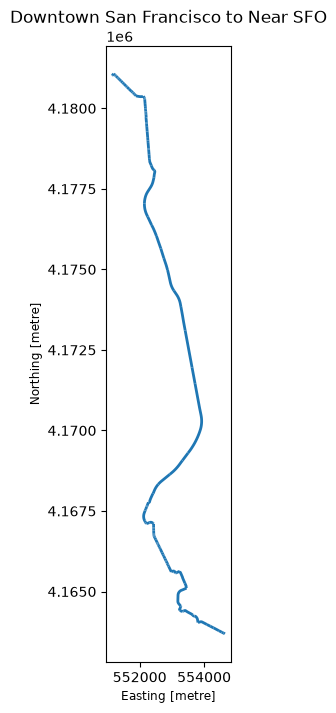

In [6]:
# Make sure a route exists
if route is None:
    raise ValueError("No route found")

# Convert route into geographic data
route_edges = ox.routing.route_to_gdf(
    G_main, route
)

# Use team's coordinate system
route_gdf = route_edges[["geometry"]].to_crs(
    "EPSG:26910"
).reset_index(drop=True)

# Calculate route distance
distance_km = route_gdf.geometry.length.sum() / 1000

print("Route distance:", round(distance_km, 2), "km")

# Plot the route
route_gdf.plot(figsize=(8, 8), linewidth=2)

plt.title("Downtown San Francisco to Near SFO")
plt.show()

In [7]:
route_gdf.to_file(
    "data/processed/sf_to_sfo_test_route.gpkg",
    driver="GPKG"
)

print("Test route saved!")

Test route saved!


## Limitations

- The driving road network is preliminary.
- Vehicle-access and turn restrictions have not been fully validated.
- The original SFO coordinate snapped to an isolated road segment.
- The connected endpoint used for the test route was approximately 332 meters from the SFO reference coordinate.
- The route minimizes driving distance, not travel time.
- Public transit routing using Brandon's GTFS data remains a separate task.